# Alinhamento espacial por DTW e detecção de anomalias

O notebook reconstrói o percurso da correia a partir do CAD, alinha coletas
inerciais à referência por DTW e projeta detecções sobre a correia.


In [1]:
import math
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from ezdxf import recover
from ezdxf.addons.drawing import Frontend, RenderContext
from ezdxf.addons.drawing.matplotlib import MatplotlibBackend
from ezdxf.math import Matrix44, Vec3
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
from plotly.subplots import make_subplots
import pandas as pd
from dtaidistance import dtw
from scipy.stats import zscore
from scipy.signal import find_peaks


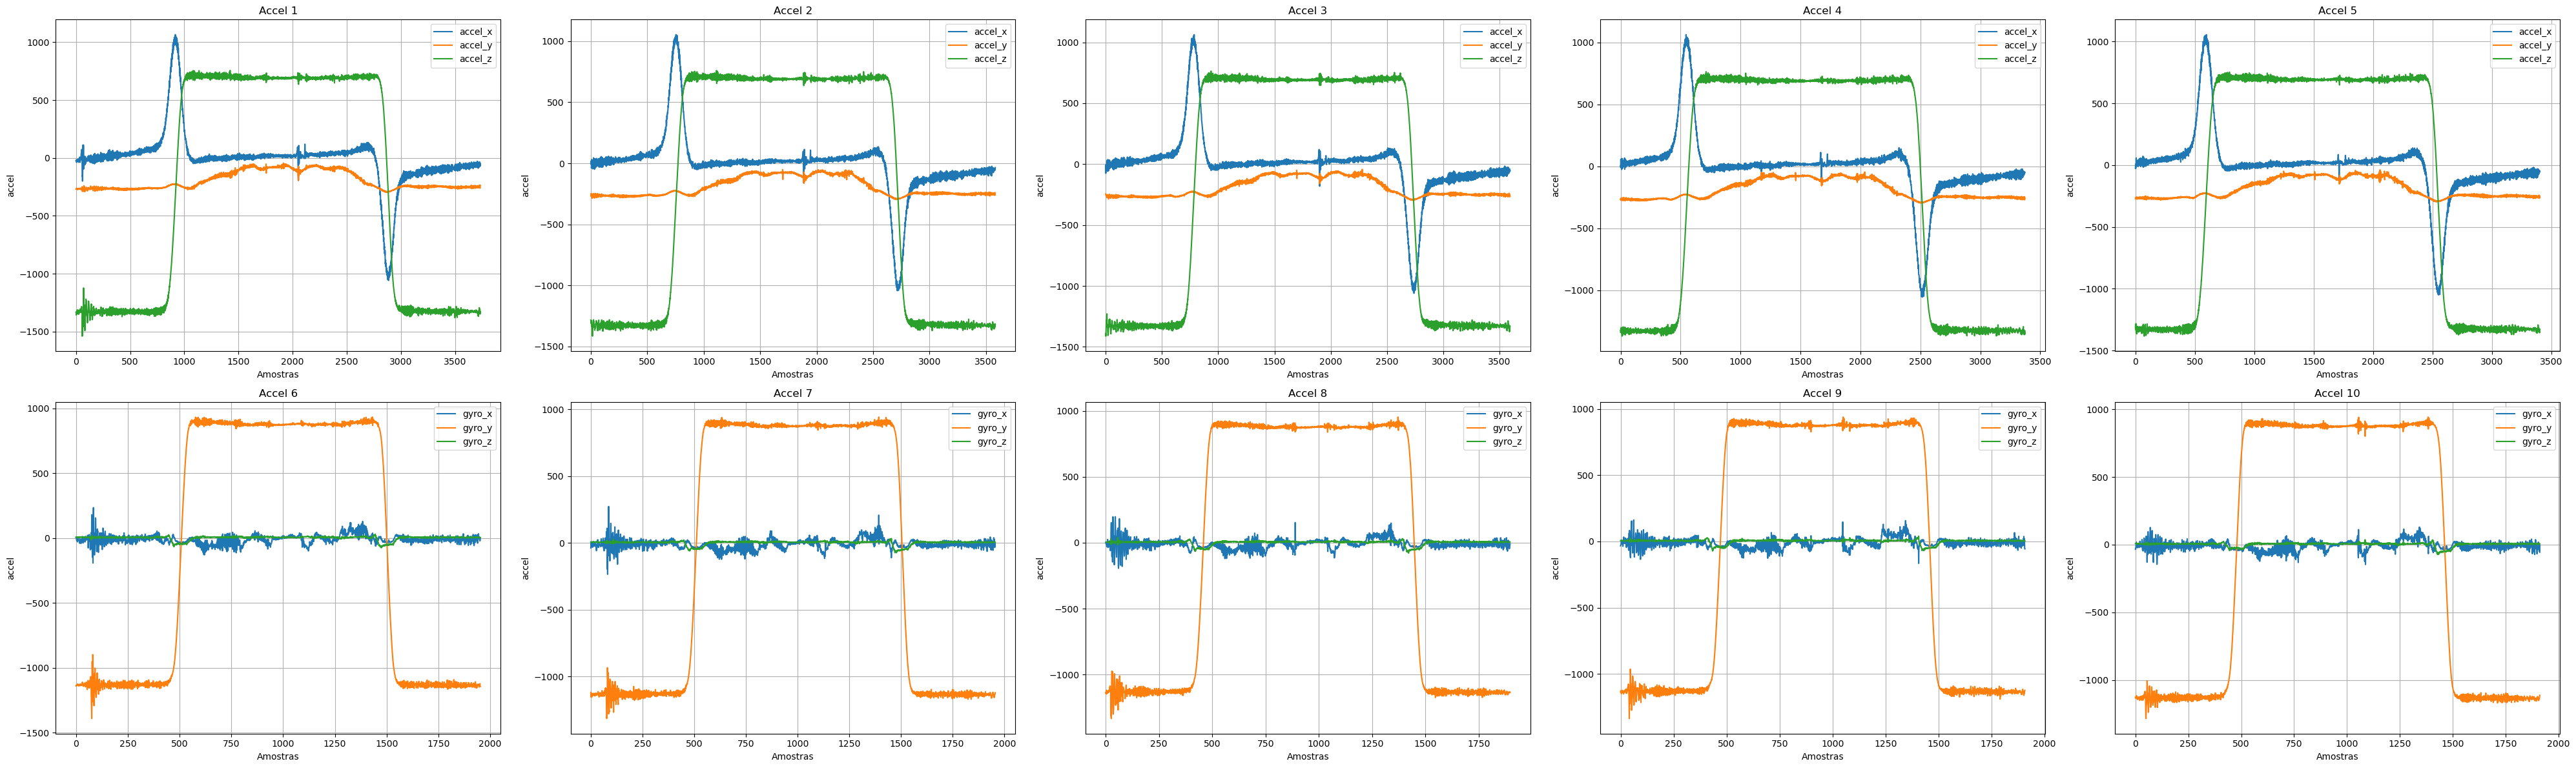

In [3]:
df_1 = pd.read_csv('C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/logs_tcp/alinhado/log_tcp_2025-11-28_15-07-19_192.168.1.116.csv')
df_2 = pd.read_csv('C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/logs_tcp/alinhado/log_tcp_2025-11-28_15-07-58_192.168.1.116.csv')
df_3 = pd.read_csv('C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/logs_tcp/alinhado/log_tcp_2025-11-28_15-08-39_192.168.1.116.csv')
df_4 = pd.read_csv('C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/logs_tcp/alinhado/log_tcp_2025-11-28_15-09-18_192.168.1.116.csv')
df_5 = pd.read_csv('C:/Users/Raiza/OneDrive/Documentos/verlab/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/SIF-DI241794-SISTEMA-INERCIAL-COM-HADRWARE-FLEX-VEL-main/receptor/logs_tcp/alinhado/log_tcp_2025-11-28_15-09-55_192.168.1.116.csv')
df_6 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_tcp_imacentral/esteira_alinhada/log_tcp_2025-11-13_19-19-45_192.168.1.131.csv')
df_7 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_tcp_imacentral/esteira_alinhada/log_tcp_2025-11-13_19-20-26_192.168.1.131.csv')
df_8 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_tcp_imacentral/esteira_alinhada/log_tcp_2025-11-13_19-21-06_192.168.1.131.csv')
df_9 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_tcp_imacentral/esteira_alinhada/log_tcp_2025-11-13_19-21-45_192.168.1.131.csv')
df_10 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_tcp_imacentral/esteira_alinhada/log_tcp_2025-11-13_19-22-25_192.168.1.131.csv')


df_list = [
    df_1, df_2, df_3, df_4, df_5,
    df_6, df_7, df_8, df_9, df_10
]

columns = [
    ['accel_x', 'accel_y', 'accel_z']] * 5 + [
    ['gyro_x', 'gyro_y', 'gyro_z']] * 5

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(40, 12))
axes = axes.flatten()

for idx, (df, cols) in enumerate(zip(df_list, columns)):
    df.plot(y=cols,
            title=f'Accel {idx+1}',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[idx],
            grid=True)

plt.tight_layout()
plt.show()


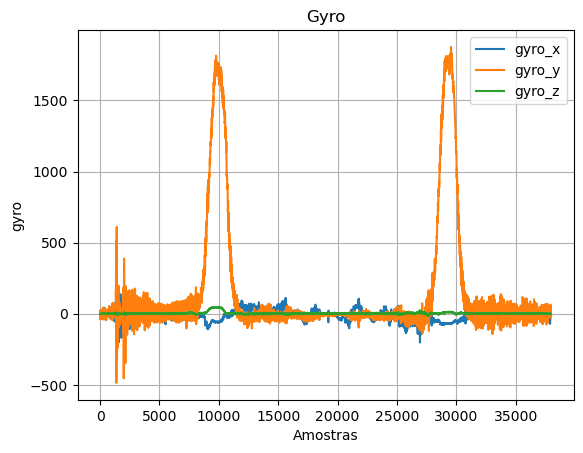

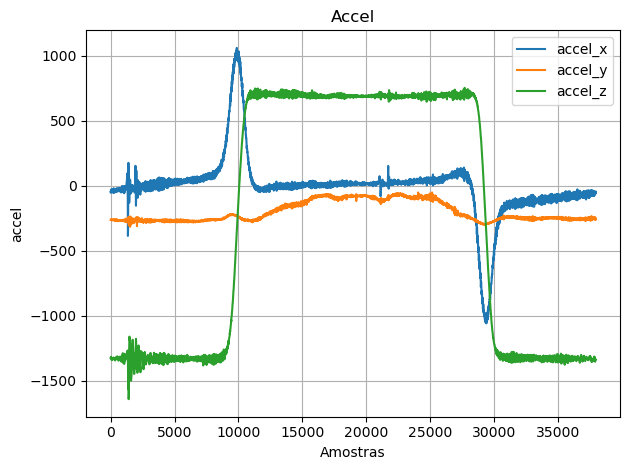

In [4]:
df = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-11-55_192.168.1.116.csv')

df.plot(y=['gyro_x', 'gyro_y', 'gyro_z'],
            x = 'timestamp_us',
            title='Gyro',
            xlabel='Amostras',
            ylabel='gyro',
            grid=True)
df.plot(y=['accel_x', 'accel_y', 'accel_z'],
            x = 'timestamp_us',
            title='Accel',
            xlabel='Amostras',
            ylabel='accel',
            grid=True)

plt.tight_layout()
plt.show()


## Reconstrução do CAD e alinhamento da coleta-base


In [5]:
try:
    doc, auditor = recover.readfile("../arquivos/esteira_ufmg_verlab-Sketch.dxf")
except IOError:
    print(f"Not a DXF file or a generic I/O error.")
except ezdxf.DXFStructureError:
    print(f"Invalid or corrupted DXF file.")


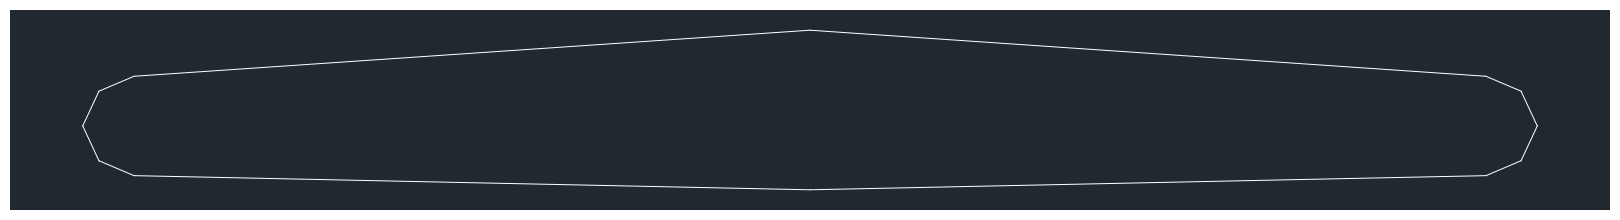

In [6]:
if not auditor.has_errors:
    fig = plt.figure()
    ax = fig.add_axes([0, 0, 1, 1])
    ctx = RenderContext(doc)
    out = MatplotlibBackend(ax)
    Frontend(ctx, out).draw_layout(doc.modelspace(), finalize=True)
    fig.savefig("your.png", dpi=300)


In [7]:
def circle_array(xc, yc, r, start, end):
    """
    Discretiza um arco circular em pontos cartesianos.
    
    Parameters
    ----------
    xc, yc : float
        Coordenadas do centro do círculo.
    r : float
        Raio do arco.
    start, end : float
        Ângulos inicial e final, em graus.
    
    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Coordenadas x e y dos pontos gerados.
    """
    phi1 = start * np.pi / 180.0
    phi2 = end * np.pi / 180.0
    dphi = (phi2 - phi1) / np.ceil(200 * np.pi * r * (phi2 - phi1))
    array = np.arange(phi1, phi2, dphi)
    return xc + r * np.cos(array), yc + r * np.sin(array)


lines = []
circles = []
arcs = []
ellipses = []
splines = []
polylines = []

msp = doc.modelspace()
for entity in msp:
    transform = Matrix44()
    if entity.dxftype() == "LINE":
        start = transform.transform(entity.dxf.start)
        end = transform.transform(entity.dxf.end)
        lines.append((start, end))
    elif entity.dxftype() == "LWPOLYLINE":
        polyline = [transform.transform((p[0], p[1], 0)) for p in entity.get_points()]
        polylines.append(polyline)
    elif entity.dxftype() == "CIRCLE":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        circles.append((center, radius))
    elif entity.dxftype() == "ARC":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        start_angle = entity.dxf.start_angle
        end_angle = entity.dxf.end_angle
        arcs.append((center, radius, start_angle, end_angle))
    elif entity.dxftype() == "ELLIPSE":
        center = transform.transform(entity.dxf.center)
        major_axis_vec = Vec3(entity.dxf.major_axis)
        transformed_major_axis = transform.transform_direction(major_axis_vec)

        major_len = transformed_major_axis.magnitude
        angle_rad = math.atan2(transformed_major_axis.y, transformed_major_axis.x)
        rotation_deg = math.degrees(angle_rad)

        ratio = entity.dxf.ratio
        ellipses.append((center, major_len, ratio, rotation_deg))
    elif entity.dxftype() == "SPLINE":
        control_points = [transform.transform(p) for p in entity.control_points]
        fit_points = [transform.transform(p) for p in entity.fit_points]
        splines.append((control_points, fit_points))

print(f"lines:{len(lines)}")
print(f"circles:{len(circles)}")
print(f"arcs:{len(arcs)}")
print(f"ellipses:{len(ellipses)}")
print(f"splines:{len(splines)}")
print(f"polylines:{len(polylines)}")


lines:12
circles:0
arcs:0
ellipses:0
splines:0
polylines:0


In [8]:
all_raw_segments = []


for line in lines:
    p1 = (line[0][0], line[0][1])
    p2 = (line[1][0], line[1][1])
    all_raw_segments.append((p1, p2))


def sort_segments(segments, tolerance=1e-5):
    """
    Ordena segmentos conectados para formar um caminho contínuo.
    
    A lista recebida é consumida durante a ordenação, pois os segmentos são
    removidos conforme são conectados. Segmentos invertidos são reorientados
    automaticamente quando necessário.
    
    Parameters
    ----------
    segments : list
        Pares de pontos que representam os segmentos.
    tolerance : float
        Distância máxima para considerar dois extremos conectados.
    
    Returns
    -------
    list
        Segmentos ordenados segundo a continuidade geométrica.
    """
    if not segments:
        return []
    sorted_path = [segments.pop(0)]
    while segments:
        current_end_point = sorted_path[-1][1]
        found_next = False
        for i, segment in enumerate(segments):
            p_start, p_end = segment
            if np.linalg.norm(np.array(current_end_point) - np.array(p_start)) < tolerance:
                sorted_path.append(segments.pop(i))
                found_next = True
                break
            elif np.linalg.norm(np.array(current_end_point) - np.array(p_end)) < tolerance:

                sorted_path.append((p_end, p_start))
                segments.pop(i)
                found_next = True
                break
        if not found_next:
            print("Nem todos os segmentos foram conectados")
            break
    return sorted_path

sorted_segments = sort_segments(all_raw_segments)
pontos_do_contorno = [segment[0] for segment in sorted_segments]
pontos_do_contorno.append(sorted_segments[-1][1])
conveyor_path = np.array(pontos_do_contorno)
conveyor_path[:, 0] = conveyor_path[:, 0] * -1


In [9]:
def interpolate_path_by_distance(path_points, num_points):
    """
    Reamostra um caminho usando pontos igualmente espaçados pela distância percorrida.
    
    Parameters
    ----------
    path_points : np.ndarray
        Coordenadas ordenadas do caminho original.
    num_points : int
        Quantidade de pontos desejada no caminho reamostrado.
    
    Returns
    -------
    tuple[np.ndarray, np.ndarray]
        Caminho interpolado e distâncias cumulativas dos vértices originais.
    """

    segment_lengths = np.sqrt(np.sum(np.diff(path_points, axis=0)**2, axis=1))


    cumulative_distances = np.zeros(len(path_points))
    cumulative_distances[1:] = np.cumsum(segment_lengths)

    total_length = cumulative_distances[-1]


    target_distances = np.linspace(0, total_length, num_points)


    interp_x = np.interp(target_distances, cumulative_distances, path_points[:, 0])
    interp_y = np.interp(target_distances, cumulative_distances, path_points[:, 1])

    interpolated_points = np.vstack((interp_x, interp_y)).T


    return interpolated_points, cumulative_distances


In [10]:
df_base = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-13-47_192.168.1.116.csv')
n_samples_base = len(df_base)
n_points_cad = len(conveyor_path)

interpolated_points_ref, original_cumulative_distances = interpolate_path_by_distance(
    conveyor_path,
    n_samples_base
)


idx_alvo_cad_original = 10


distancia_alvo = original_cumulative_distances[idx_alvo_cad_original]


total_length = original_cumulative_distances[-1]
target_distances_interp = np.linspace(0, total_length, n_samples_base)
idx_alvo_interpolado = np.argmin(np.abs(target_distances_interp - distancia_alvo))

print(f"distancia real: {distancia_alvo:.2f}")
print(f"indice correspondente no array de {n_samples_base} pontos: {idx_alvo_interpolado}")


s_sensor = df_base['accel_z'].head(int(len(df_base)/2)).values
derivada = np.gradient(s_sensor)
threshold = np.std(s_sensor) * 0.1
indices_perto_de_zero = np.where(np.abs(s_sensor) < threshold)[0]

if len(indices_perto_de_zero) == 0:
    print("nenhum ponto perto de zero")
else:
    idx_ponto_alvo_sensor = indices_perto_de_zero[np.argmax(np.abs(derivada[indices_perto_de_zero]))]

print(f"ponto que corresponde ao meio da curva do accel_z: {idx_ponto_alvo_sensor}")


offset = idx_alvo_interpolado - idx_ponto_alvo_sensor
print(f"Offset: {offset}")

df_base_alinhado = df_base.copy()
colunas_sensores = ['accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z', 'temp', 'timestamp_us']

for col in colunas_sensores:
    if col in df_base_alinhado.columns:
        df_base_alinhado[col] = np.roll(df_base_alinhado[col].values, offset)


distancia real: 1840.36
indice correspondente no array de 3485 pontos: 3396
ponto que corresponde ao meio da curva do accel_z: 689
Offset: 2707


In [11]:
df_base = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-23-23_192.168.1.116.csv')
n_points_cad = len(conveyor_path)


idx_ponto_1_cad_original = 10
idx_ponto_2_cad_original = 4


ponto_1 = df_base['accel_x'].argmax()
ponto_2 = df_base['accel_x'].argmin()

print(f"ponto que corresponde ao meio da curva 1 do accel_x: {ponto_1}")
print(f"ponto que corresponde ao meio da curva 2 do accel_x: {ponto_2}")


if ponto_1 > ponto_2:
    ponto_1, ponto_2 = ponto_2, ponto_1


pontos_entre = ponto_2 - ponto_1

print(f"Pontos entre ponto_1 ({ponto_1}) e ponto_2 ({ponto_2}): {pontos_entre}")

tam_interp_esteira = (pontos_entre) * 2

print(f'tamanho da esteira: {len(df_base)}')


gap = int(tam_interp_esteira - len(df_base))
print(f'gap: {gap}')


if gap > 0:

    n_range = int(len(df_base) * 0.10)
    if n_range < 1: n_range = 1


    subset_dados = df_base.iloc[-n_range:]


    valores_mediana = subset_dados.median()


    dados_pad = np.tile(valores_mediana.values, (gap, 1))

    df_pad = pd.DataFrame(dados_pad, columns=df_base.columns)


    df_base = pd.concat([df_pad, df_base], axis=0, ignore_index=True)

n_samples_base = len(df_base)

interpolated_points_ref, original_cumulative_distances = interpolate_path_by_distance(
    conveyor_path,
    n_samples_base
)

print(f'interp: {len(interpolated_points_ref)}')


distancia_ponto_1 = original_cumulative_distances[idx_ponto_1_cad_original]
distancia_ponto_2 = original_cumulative_distances[idx_ponto_2_cad_original]


total_length = original_cumulative_distances[-1]
target_distances_interp = np.linspace(0, total_length, n_samples_base)

idx_ponto_1_interpolado = np.argmin(np.abs(target_distances_interp - distancia_ponto_1))
idx_ponto_2_interpolado = np.argmin(np.abs(target_distances_interp - distancia_ponto_2))

print(f"Distancia real ponto 1: {distancia_ponto_1:.2f}")
print(f"Indice interpolado ponto 1: {idx_ponto_1_interpolado}")

print(f"Distancia real ponto 2: {distancia_ponto_2:.2f}")
print(f"Indice interpolado ponto 2: {idx_ponto_2_interpolado}")


offset = idx_ponto_1_interpolado - (ponto_1)
print(f"Offset calculado: {offset}")

df_base_alinhado = df_base.copy()
colunas_sensores = ['accel_x', 'accel_y', 'accel_z', 'gyro_x', 'gyro_y', 'gyro_z', 'temp', 'timestamp_us']

for col in colunas_sensores:
    if col in df_base_alinhado.columns:
        df_base_alinhado[col] = np.roll(df_base_alinhado[col].values, offset)

print(f"Tamanho do df_base final: {len(df_base_alinhado)}")


ponto que corresponde ao meio da curva 1 do accel_x: 1095
ponto que corresponde ao meio da curva 2 do accel_x: 3006
Pontos entre ponto_1 (1095) e ponto_2 (3006): 1911
tamanho da esteira: 3857
gap: -35
interp: 3857
Distancia real ponto 1: 1840.36
Indice interpolado ponto 1: 3758
Distancia real ponto 2: 897.11
Indice interpolado ponto 2: 1832
Offset calculado: 2663
Tamanho do df_base final: 3857


In [12]:
hover_texts_alinhados = []
for index, row in df_base_alinhado.iterrows():
    text = (f"<b>accel_x:</b> {row['accel_x']:.2f}<br><b>accel_y:</b> {row['accel_y']:.2f}<br><b>accel_z:</b> {row['accel_z']:.2f}<br>" +
            f"<b>gyro_x:</b> {row['gyro_x']:.4f}<br><b>gyro_y:</b> {row['gyro_y']:.4f}<br><b>gyro_z:</b> {row['gyro_z']:.4f}</br>" +
            f"<b>temp:</b> {row['temp']}<br>")
    hover_texts_alinhados.append(text)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0], y=conveyor_path[:, 1], mode='lines',
    line=dict(color='black', width=2), name='Esteira'
))
fig.add_trace(go.Scatter(
    x=interpolated_points_ref[:, 0], y=interpolated_points_ref[:, 1],
    mode='markers',

    marker=dict(size=6, color=df_base_alinhado['accel_z'],
                colorscale='Viridis', showscale=True,
                colorbar=dict(title='accel_x')),

    hoverinfo='text',
    hovertext=hover_texts_alinhados,
    name='Dados do Log'
))

fig.update_layout(
    title="Plot alinhado pela curva e accel_z",
    yaxis_scaleanchor="x", yaxis_scaleratio=1,
    showlegend=True, width=900, height=700
)

fig.show()


c:\Users\Raiza\anaconda3\Lib\site-packages\kaleido\_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




## Alinhamento DTW das coletas normais


In [13]:
df_1 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-07-19_192.168.1.116.csv')
df_2 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-07-58_192.168.1.116.csv')
df_3 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-08-39_192.168.1.116.csv')
df_4 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-09-18_192.168.1.116.csv')
df_5 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-09-55_192.168.1.116.csv')
df_6 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-18-56_192.168.1.116.csv')
df_7 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-19-33_192.168.1.116.csv')
df_8 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-20-50_192.168.1.116.csv')
df_9 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-21-28_192.168.1.116.csv')
df_10 = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/alinhado/log_tcp_2025-11-28_15-13-47_192.168.1.116.csv')


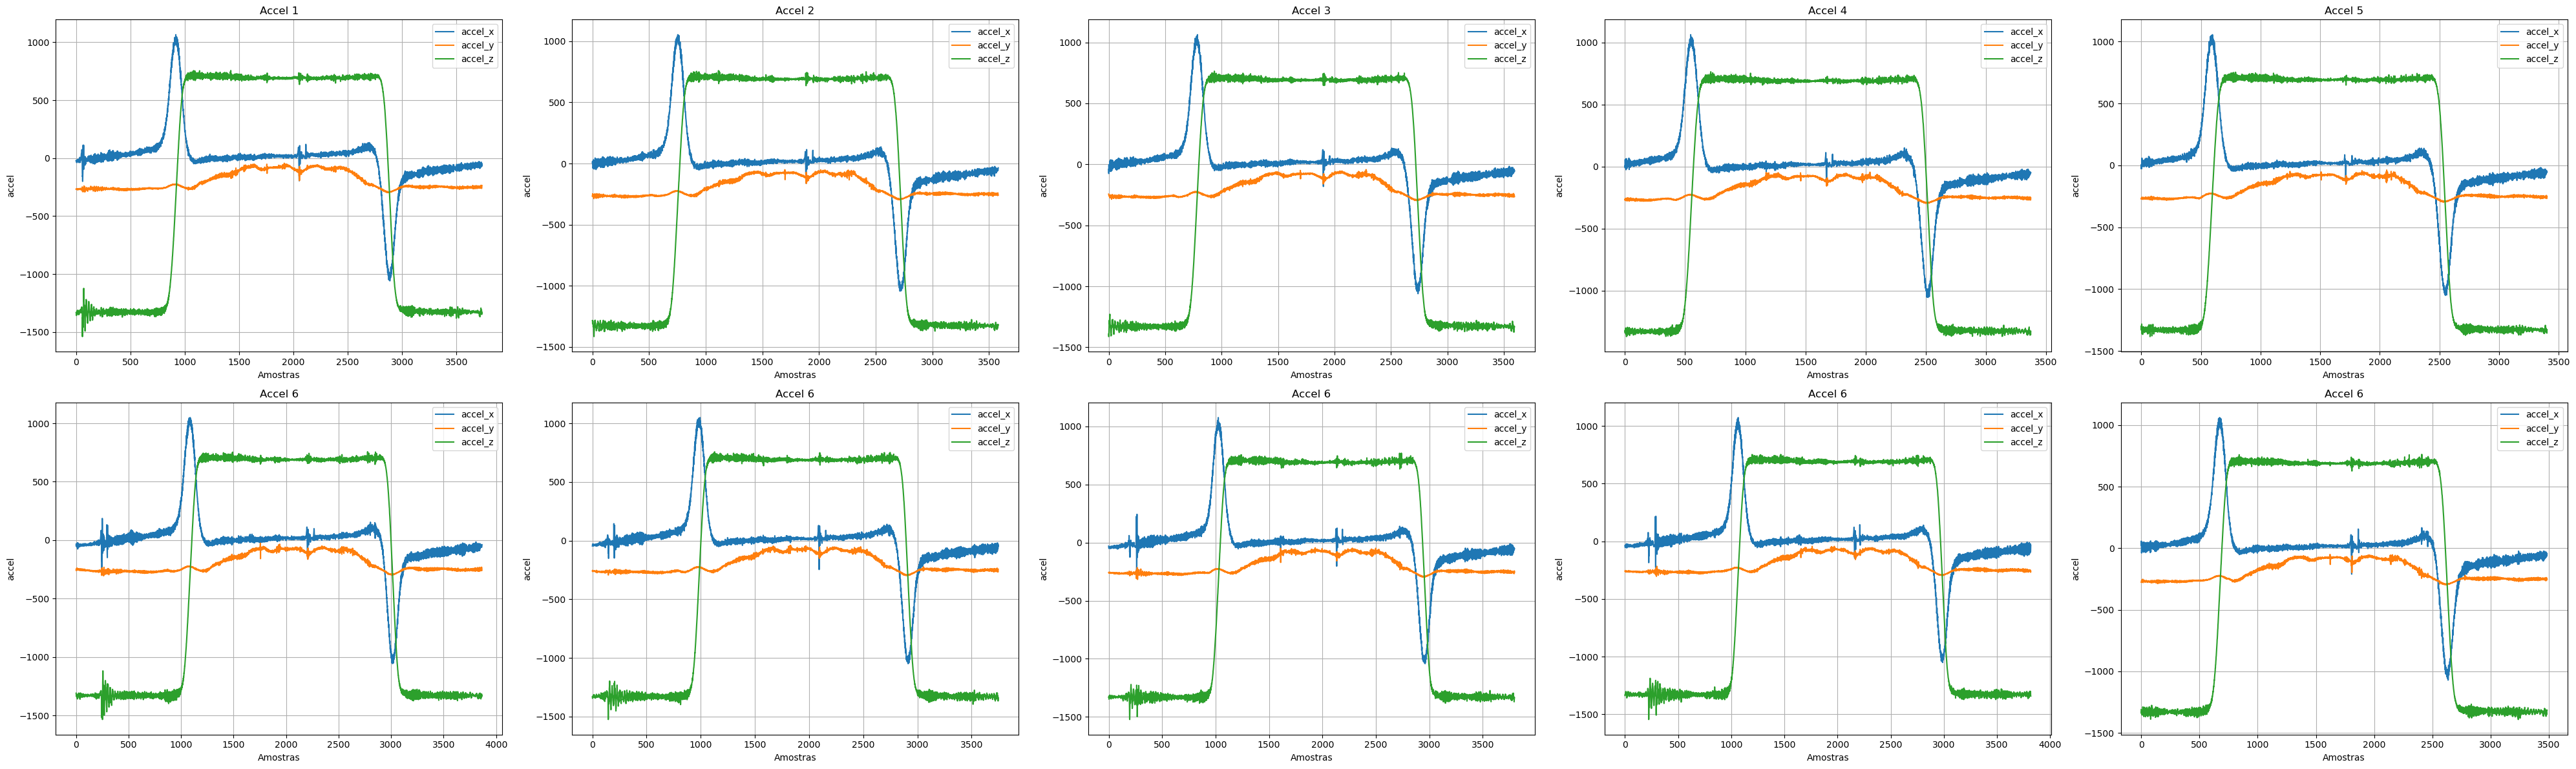

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(40, 12))

df_1.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 1',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0,0],
            grid=True)
df_2.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 2',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0,1],
            grid=True)
df_3.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 3',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0,2],
            grid=True)
df_4.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 4',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 3],
            grid=True)
df_5.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 5',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0, 4],
            grid=True)
df_6.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 0],
            grid=True)
df_7.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 1],
            grid=True)
df_8.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 2],
            grid=True)
df_9.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 3],
            grid=True)
df_10.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Accel 6',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1, 4],
            grid=True)

plt.tight_layout()
plt.show()


In [15]:
base_signal = df_base['accel_z'].values
base_signal_norm = zscore(base_signal)

df_list = [
    df_1, df_2, df_3, df_4, df_5,
    df_6, df_7, df_8, df_9, df_10
]

normalized_signals = [zscore(df['accel_z'].values) for df in df_list]


In [16]:
distancias = []
alinhamentos = []

for i in range(len(normalized_signals)):
    warping_path, distancia_dtw = dtw.warping_path(base_signal_norm, normalized_signals[i],
                                                    include_distance = True)

    distancias.append(distancia_dtw)
    alinhamentos.append(warping_path)

    print(f"Distância/custo do alinhamento {i + 1}: {distancia_dtw}")


std_dev_distances = np.std(distancias)

print(f"Distância Média: {np.mean(distancias):.4f}")
print(f"Desvio Padrão das Distâncias: {std_dev_distances:.4f}")


Distância/custo do alinhamento 1: 1.4525907178580724
Distância/custo do alinhamento 2: 2.8873276458401613
Distância/custo do alinhamento 3: 2.160139538034093
Distância/custo do alinhamento 4: 6.111219832647946
Distância/custo do alinhamento 5: 5.542557281981764
Distância/custo do alinhamento 6: 0.6255299036193122
Distância/custo do alinhamento 7: 1.1984052211475047
Distância/custo do alinhamento 8: 0.9435482466268685
Distância/custo do alinhamento 9: 0.7594339890840324
Distância/custo do alinhamento 10: 3.8668800865694197
Distância Média: 2.5548
Desvio Padrão das Distâncias: 1.9016


In [17]:
print(f"Tamanho df_base: {len(base_signal_norm)}")
for i in range(len(alinhamentos)):
    print(f"Tamanho alinhamento {i + 1}: {len(alinhamentos[i])}")


Tamanho df_base: 3857
Tamanho alinhamento 1: 7175
Tamanho alinhamento 2: 7123
Tamanho alinhamento 3: 7128
Tamanho alinhamento 4: 6929
Tamanho alinhamento 5: 6973
Tamanho alinhamento 6: 4924
Tamanho alinhamento 7: 6652
Tamanho alinhamento 8: 6087
Tamanho alinhamento 9: 5445
Tamanho alinhamento 10: 7016


In [18]:
def reduce_paths(alinhamentos, df_list, df_base_len, channel,
                                          window_halfwidth=2, selection='local_var'):
    """
    Converte caminhos DTW em uma matriz alinhada à referência.
    
    Para cada índice da coleta-base, seleciona um valor entre os índices
    correspondentes de cada coleta. A seleção pode usar o primeiro ou último
    candidato, o maior ou menor desvio da mediana, ou a maior variância local.
    
    Parameters
    ----------
    alinhamentos : list
        Caminhos DTW formados por pares ``(indice_base, indice_coleta)``.
    df_list : list[pd.DataFrame]
        Coletas que serão projetadas sobre a referência.
    df_base_len : int
        Comprimento da coleta-base.
    channel : str
        Coluna utilizada no alinhamento.
    window_halfwidth : int
        Metade da janela empregada no cálculo da variância local.
    selection : str
        Critério usado quando vários índices correspondem à mesma posição.
    
    Returns
    -------
    np.ndarray
        Matriz com uma linha por posição da referência e uma coluna por coleta.
    """
    n_runs = len(alinhamentos)
    aligned = np.full((df_base_len, n_runs), np.nan, dtype=float)

    for k in range(n_runs):
        path = alinhamentos[k]
        seq = df_list[k][channel].values

        groups = defaultdict(list)
        for i, j in path:
            groups[int(i)].append(int(j))

        for i in range(df_base_len):
            if i not in groups:

                continue
            js = sorted(set(groups[i]))
            if len(js) == 1:
                aligned[i, k] = seq[js[0]]
                continue


            if selection == 'first':
                chosen_j = js[0]
            elif selection == 'last':
                chosen_j = js[-1]
            elif selection == 'max_dev':
                vals = np.array([seq[j] for j in js])
                med = np.median(vals)
                chosen_idx = np.argmax(np.abs(vals - med))
                chosen_j = js[chosen_idx]
            elif selection == 'median_dev':
                vals = np.array([seq[j] for j in js])
                med = np.median(vals)
                chosen_idx = np.argmin(np.abs(vals - med))
                chosen_j = js[chosen_idx]
            elif selection == 'local_var':

                variances = []
                for j in js:
                    a = max(0, j - window_halfwidth)
                    b = min(len(seq), j + window_halfwidth + 1)
                    window_vals = seq[a:b]
                    if len(window_vals) == 0:
                        variances.append(-np.inf)
                    else:
                        variances.append(np.var(window_vals))
                chosen_idx = int(np.argmax(variances))
                chosen_j = js[chosen_idx]
            else:
                raise ValueError("selection inválido")
            aligned[i, k] = seq[chosen_j]

    return aligned


In [19]:
aligned_matrix = reduce_paths(alinhamentos, df_list, len(df_base),
                                                       channel='accel_z', window_halfwidth=2,
                                                       selection='local_var')

base_vector = df_base['accel_z'].to_numpy().reshape(-1, 1)
aligned_plus_base = np.concatenate([aligned_matrix, base_vector], axis=1)


print("aligned shape:", aligned_matrix.shape)
print("aligned_plus_base shape:", aligned_plus_base.shape)

valid_counts_per_point = np.sum(~np.isnan(aligned_plus_base), axis=1)
print("min/mean/max valid counts per base point:", valid_counts_per_point.min(),
      valid_counts_per_point.mean(), valid_counts_per_point.max())


std_per_point = np.nanstd(aligned_plus_base, axis=1)
mean_per_point = np.nanmean(aligned_plus_base, axis=1)
median_per_point = np.nanmedian(aligned_plus_base, axis=1)


if len(df_base) == len(std_per_point):
    df_base['aligned_std_accel_z'] = std_per_point
    df_base['aligned_mean_accel_z'] = mean_per_point
    df_base['aligned_median_accel_z'] = median_per_point
    print("Colunas adicionadas ao df_base: aligned_std_accel_z, aligned_mean_accel_z, aligned_median_accel_z")
else:
    print("Comprimento mismatch: df_base", len(df_base), "vs std array", len(std_per_point))


aligned shape: (3857, 10)
aligned_plus_base shape: (3857, 11)
min/mean/max valid counts per base point: 11 11.0 11
Colunas adicionadas ao df_base: aligned_std_accel_z, aligned_mean_accel_z, aligned_median_accel_z


In [20]:
col = "accel_z"
x_base = df_base["timestamp"] if "timestamp" in df_base.columns else np.arange(len(df_base))

mean = df_base[f"aligned_mean_{col}"]
std = df_base[f"aligned_std_{col}"]
upper = mean + std
lower = mean - std
raw = df_base[col]


fig = go.Figure()

fig.add_trace(go.Scatter(
    x=np.concatenate([x_base, x_base[::-1]]),
    y=np.concatenate([upper, lower[::-1]]),
    fill='toself',
    fillcolor='rgba(0, 150, 255, 0.2)',
    line=dict(color='rgba(255,255,255,0)'),
    hoverinfo="skip",
    showlegend=True,
    name="±1 desvio padrão"
))

fig.add_trace(go.Scatter(
    x=x_base,
    y=mean,
    mode='lines',
    line=dict(color='blue', width=2),
    name='Média alinhada'
))

fig.add_trace(go.Scatter(
    x=x_base,
    y=raw,
    mode='lines',
    line=dict(color='orange', width=1),
    name='Coleta base'
))

fig.update_layout(
    title=f"Série temporal alinhada com bandas de confiança ({col})",
    xaxis_title="Tempo (ajustado pelo offset)",
    yaxis_title=col,
    hovermode="x unified",
    template="plotly_dark",
    legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="right",
        x=0.99,
        bgcolor="rgba(0,0,0,0.5)",
        bordercolor="rgba(255,255,255,0.2)",
        borderwidth=1
    )
)

fig.show()


In [21]:
col = "accel_z"
k = 3

x_base = df_base["timestamp"] - offset if "timestamp" in df_base.columns else np.arange(len(df_base))

mean = df_base[f"aligned_mean_{col}"]
std = df_base[f"aligned_std_{col}"]
upper = mean + k*std
lower = mean - k*std
raw = df_base[col]


anomaly_mask = (raw > mean + k*std) | (raw < mean - k*std)
x_anom = x_base[anomaly_mask]
y_anom = raw[anomaly_mask]

print(f"{anomaly_mask.sum()} anomalias detectadas com k={k}")

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=np.concatenate([x_base, x_base[::-1]]),
    y=np.concatenate([upper, lower[::-1]]),
    fill='toself',
    fillcolor='rgba(0, 150, 255, 0.2)',
    line=dict(color='rgba(255,255,255,0)'),
    hoverinfo="skip",
    name="±3 desvio padrão"
))

fig.add_trace(go.Scatter(
    x=x_base,
    y=mean,
    mode='lines',
    line=dict(color='blue', width=2),
    name='Média alinhada'
))

fig.add_trace(go.Scatter(
    x=x_base,
    y=raw,
    mode='lines',
    line=dict(color='orange', width=1),
    name='Coleta base'
))

fig.add_trace(go.Scatter(
    x=x_anom,
    y=y_anom,
    mode='markers',
    marker=dict(color='red', size=6, symbol='x'),
    name='Anomalias detectadas'
))

fig.update_layout(
    title=f"Detecção automática de anomalias — {col}",
    xaxis_title="Tempo/tamanho coleta",
    yaxis_title=col,
    hovermode="x unified",
    template="plotly_dark",
    legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="right",
        x=0.99,
        bgcolor="rgba(0,0,0,0.5)",
        bordercolor="rgba(255,255,255,0.2)",
        borderwidth=1
    )
)

fig.show()


0 anomalias detectadas com k=3


In [22]:
col = "accel_z"
k = 3

mean_col = f"aligned_mean_{col}"
std_col  = f"aligned_std_{col}"

anomaly_mask_temporal = (
    (df_base[col] > df_base[mean_col] + k*df_base[std_col]) |
    (df_base[col] < df_base[mean_col] - k*df_base[std_col])
)
print(f"{anomaly_mask_temporal.sum()} anomalias detectadas para {col} (temporal, k={k})")

anomaly_mask_spatial = np.roll(anomaly_mask_temporal, offset)

x_points = interpolated_points_ref[:, 0]
y_points = interpolated_points_ref[:, 1]


fig = go.Figure()

fig.add_trace(go.Scatter(x=conveyor_path[:,0], y=conveyor_path[:,1],
                         mode='lines', line=dict(color='black', width=2), name='Esteira'))

fig.add_trace(go.Scatter(
    x=x_points[~anomaly_mask_spatial],
    y=y_points[~anomaly_mask_spatial],
    mode='markers',
    marker=dict(
        size=6,
        color=df_base_alinhado["accel_y"][~anomaly_mask_spatial],
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title="accel_y")
    ),
    hoverinfo='text',
    name='Pontos normais'
))

fig.add_trace(go.Scatter(
    x=x_points[anomaly_mask_spatial],
    y=y_points[anomaly_mask_spatial],
    mode='markers',
    marker=dict(color='red', size=8, symbol='x'),
    name='Anomalias detectadas'
))

fig.update_layout(
    title=f"Alinhamento ao CAD (detecção temporal, visualização espacial) — {col}",
    yaxis_scaleanchor="x", yaxis_scaleratio=1, showlegend=True,
    width=900, height=700, template="plotly_dark"
)

fig.show()


0 anomalias detectadas para accel_z (temporal, k=3)


## Avaliação com uma coleta anômala


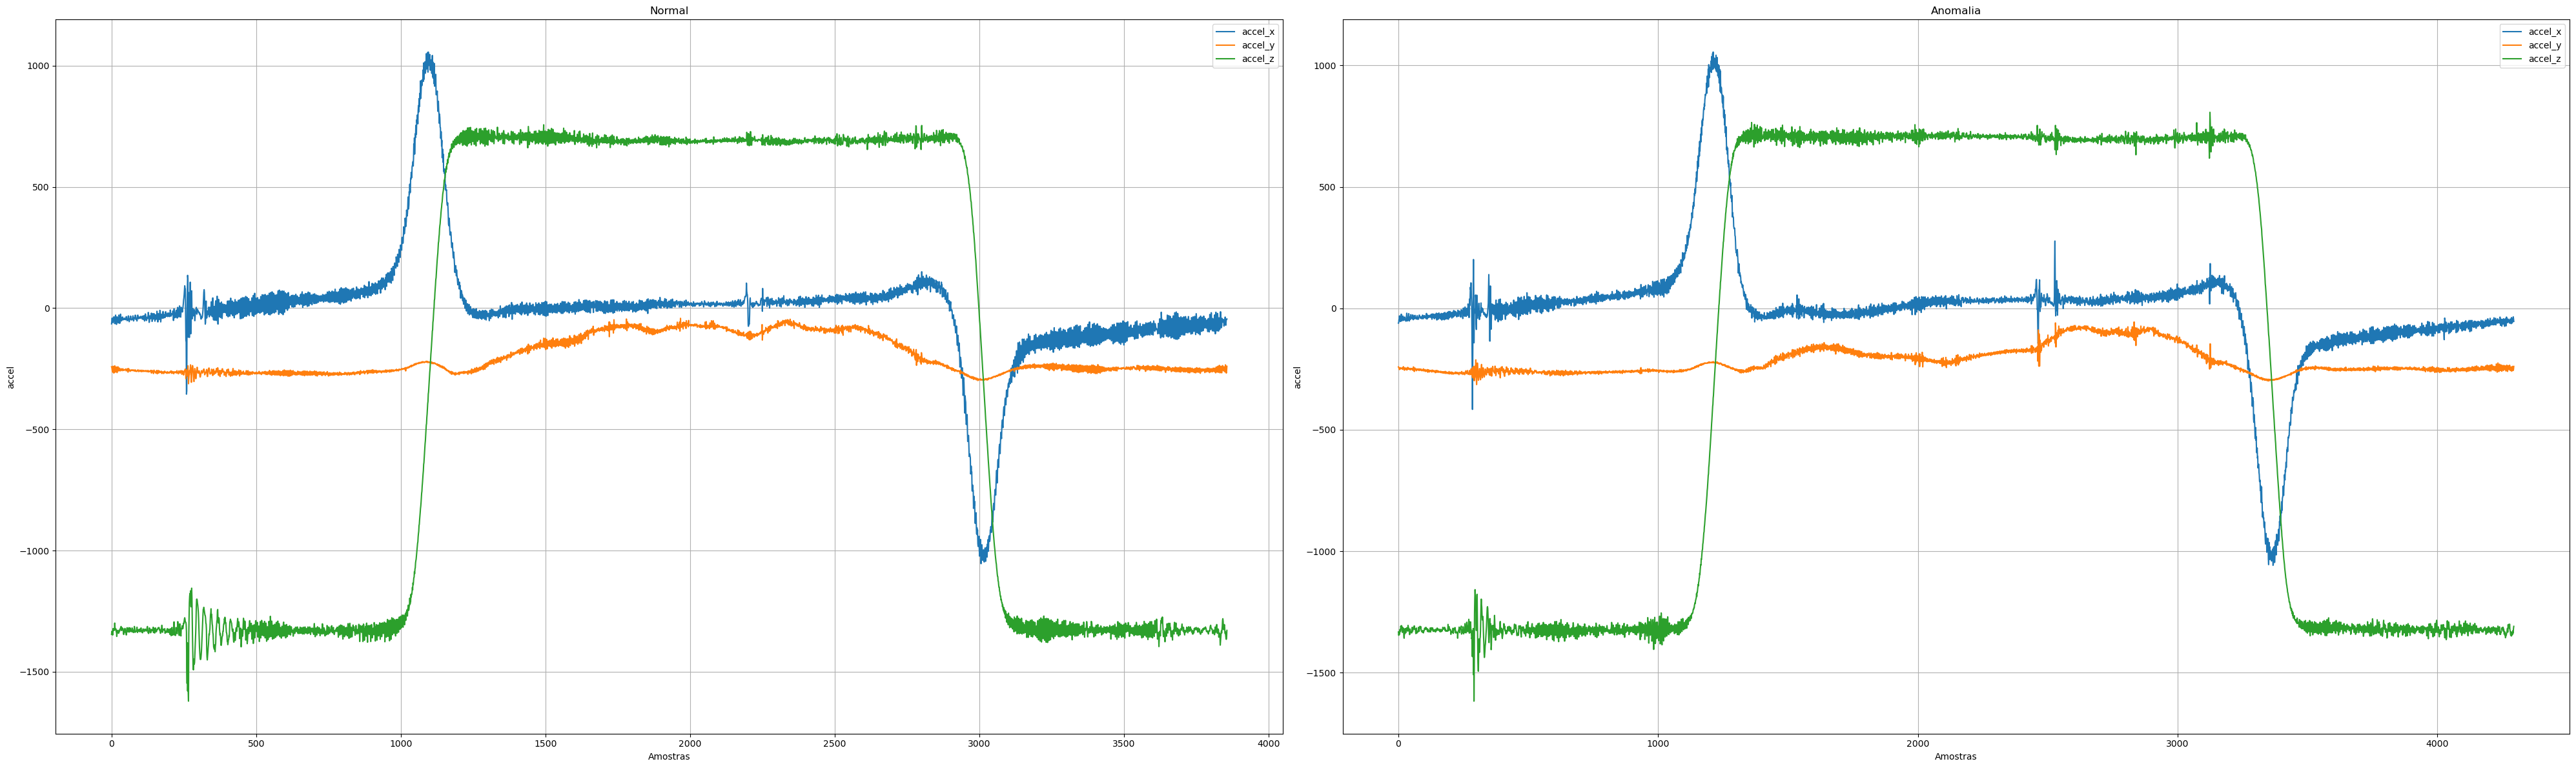

In [23]:
df_anomalia = pd.read_csv('../arquivos/logs/logs_sensor_vale/logs_centro_timestamp/an_sem_roletes_1_2/log_tcp_2025-11-28_17-08-11_192.168.1.116.csv')


fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(40, 12))

df_base.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Normal',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[0],
            grid=True)
df_anomalia.plot(y=['accel_x', 'accel_y', 'accel_z'],
            title='Anomalia',
            xlabel='Amostras',
            ylabel='accel',
            ax=axes[1],
            grid=True)

plt.tight_layout()
plt.show()


In [24]:
anomalia_signal = df_anomalia['accel_z'].values
anomalia_signal_norm = zscore(anomalia_signal)

warping_path_anomalia, distancia_dtw_anomalia = dtw.warping_path(base_signal_norm, anomalia_signal_norm,
                                                                 include_distance = True,
                                                                 penalty=0.1)

print(f"Distância/custo do alinhamento com anomalia: {distancia_dtw_anomalia}")
print(f"Tamanho alinhamento: {len(warping_path_anomalia)}")
print(f"Tamanho que deveria ter: {len(base_signal_norm)}")


df_anomalia_alinhado = reduce_paths([warping_path_anomalia], [df_anomalia], len(df_base),
                                                       channel='accel_z', window_halfwidth=2, selection='median_dev')


Distância/custo do alinhamento com anomalia: 2.3533099509636544
Tamanho alinhamento: 4338
Tamanho que deveria ter: 3857


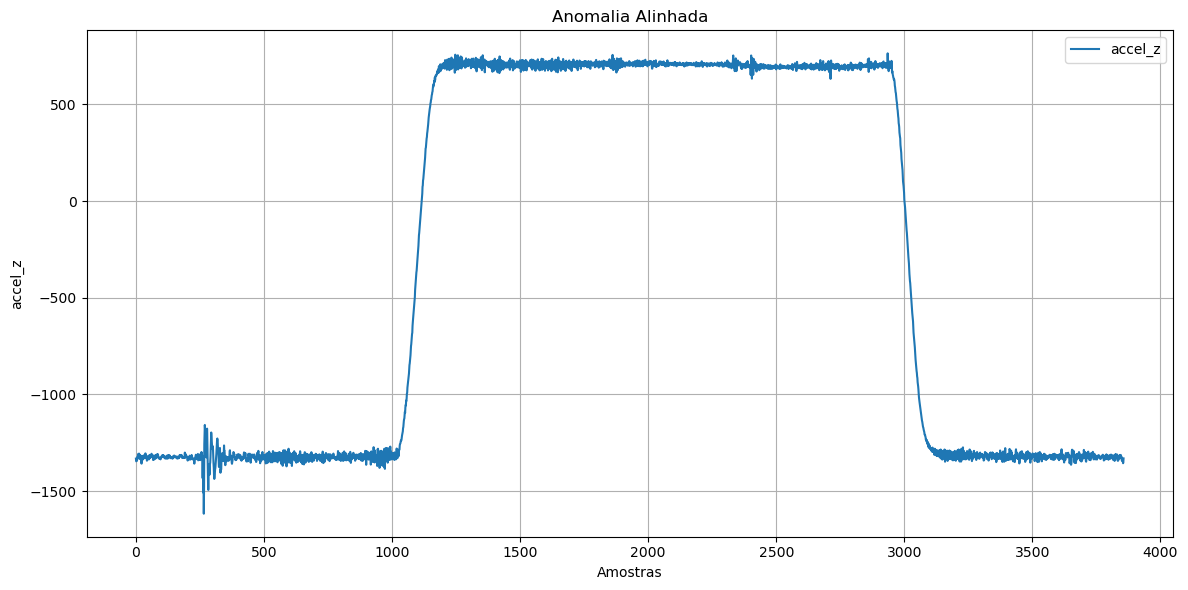

In [25]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(12, 6))


df_anomalia_alinhado_plot = pd.DataFrame(df_anomalia_alinhado, columns=['accel_z'])

df_anomalia_alinhado_plot.plot(y=['accel_z'],
            title='Anomalia Alinhada',
            xlabel='Amostras',
            ylabel='accel_z',
            ax=axes,
            grid=True)

plt.tight_layout()
plt.show()


In [26]:
col = "accel_z"
k = 3

mean_col = f"aligned_mean_{col}"
std_col  = f"aligned_std_{col}"


anomalia_aligned_values = df_anomalia_alinhado[:, 0]

anomaly_mask_temporal = (
    (anomalia_aligned_values > df_base[mean_col].values + k*df_base[std_col].values) |
    (anomalia_aligned_values < df_base[mean_col].values - k*df_base[std_col].values)
)

print(f"{anomaly_mask_temporal.sum()} anomalias detectadas para {col} (temporal, k={k})")


filtered_mask = np.zeros_like(anomaly_mask_temporal, dtype=bool)
consecutive_count = 0
start_idx = None

ConAn = 3

for i in range(len(anomaly_mask_temporal)):
    if anomaly_mask_temporal[i]:
        if consecutive_count == 0:
            start_idx = i
        consecutive_count += 1
    else:
        if consecutive_count >=ConAn:
            filtered_mask[start_idx:i] = True
        consecutive_count = 0


if consecutive_count >= 5:
    filtered_mask[start_idx:] = True

anomaly_mask_spatial = np.roll(filtered_mask, offset)

x_points = interpolated_points_ref[:, 0]
y_points = interpolated_points_ref[:, 1]
color_values = np.roll(anomalia_aligned_values, offset)

print(f"{filtered_mask.sum()} anomalias detectadas (sequências de pelo menos {ConAn})")

fig = go.Figure()


fig.add_trace(go.Scatter(
    x=conveyor_path[:, 0],
    y=conveyor_path[:, 1],
    mode='lines',
    line=dict(color='black', width=2),
    name='Esteira'
))


fig.add_trace(go.Scatter(
    x=x_points[~anomaly_mask_spatial],
    y=y_points[~anomaly_mask_spatial],
    mode='markers',
    marker=dict(
        size=6,
        color=color_values[~anomaly_mask_spatial],
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title="accel_z"),
    ),
    name='Pontos normais',
    hoverinfo='skip'
))


fig.add_trace(go.Scatter(
    x=x_points[anomaly_mask_spatial],
    y=y_points[anomaly_mask_spatial],
    mode='markers',
    marker=dict(color='red', size=8, symbol='x'),
    name='Anomalias detectadas',
    hoverinfo='skip'
))

fig.update_layout(
    title=f"Alinhamento ao CAD (detecção temporal, visualização espacial) — {col}",
    yaxis_scaleanchor="x",
    yaxis_scaleratio=1,
    showlegend=True,
    width=900,
    height=700,
    template="plotly_dark"
)

fig.show()


46 anomalias detectadas para accel_z (temporal, k=3)
7 anomalias detectadas (sequências de pelo menos 3)


In [27]:
col = "accel_z"
k = 3


raw = df_anomalia_alinhado[:, 0]
x_aligned = np.arange(len(raw))


mean = df_base[f"aligned_mean_{col}"].values
std  = df_base[f"aligned_std_{col}"].values

upper = mean + k*std
lower = mean - k*std


anomaly_mask = (raw > mean + k*std) | (raw < mean - k*std)


filtered_mask = np.zeros_like(anomaly_mask, dtype=bool)
consecutive_count = 0
start_idx = None

ConAn = 2

for i in range(len(anomaly_mask)):
    if anomaly_mask[i]:
        if consecutive_count == 0:
            start_idx = i
        consecutive_count += 1
    else:
        if consecutive_count >= ConAn:
            filtered_mask[start_idx:i] = True
        consecutive_count = 0


if consecutive_count >= 5:
    filtered_mask[start_idx:] = True

print(f"{filtered_mask.sum()} anomalias detectadas (sequências de pelo menos {ConAn})")

x_anom = x_aligned[filtered_mask]
y_anom = raw[filtered_mask]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=np.concatenate([x_aligned, x_aligned[::-1]]),
    y=np.concatenate([upper, lower[::-1]]),
    fill='toself',
    fillcolor='rgba(0, 150, 255, 0.2)',
    line=dict(color='rgba(255,255,255,0)'),
    hoverinfo="skip",
    name="±3 desvio padrão"
))

fig.add_trace(go.Scatter(
    x=x_aligned,
    y=mean,
    mode='lines',
    line=dict(color='blue', width=2),
    name='Média alinhada'
))

fig.add_trace(go.Scatter(
    x=x_aligned,
    y=raw,
    mode='lines',
    line=dict(color='orange', width=1),
    name='Anomalia (alinhada)'
))

fig.add_trace(go.Scatter(
    x=x_anom,
    y=y_anom,
    mode='markers',
    marker=dict(color='red', size=6, symbol='x'),
    name='Anomalias detectadas'
))

fig.update_layout(
    title=f"Detecção automática de anomalias — {col} (≥{ConAn} consecutivas)",
    template="plotly_dark",
)

fig.show()


15 anomalias detectadas (sequências de pelo menos 2)
